In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add the parent directory to Python path so we can import from src
import sys
import os
parent_dir = os.path.dirname(os.getcwd())
sys.path.append(parent_dir)

from src.tree_bstats.balance_index_coefficients import BalanceIndexCoefficients
from src.tree_bstats.clade_basis import clade_mean, clade_cov_matrix
from src.tree_bstats.daughter_basis import daughter_mean, daughter_cov_matrix
from src.tree_bstats.tree import Tree
from src.tree_bstats.unlabelled_tree import UnlabelledTree
from src.tree_bstats.plotting_params import plot_params

# Main text figures

# Figure 2: mean of 17 balance indices represented by the daughter-number basis

In [2]:
mean = []
min_n = 4
max_n = 100
indices = BalanceIndexCoefficients().get_daughter_labels()

# For all n in the range, we will compute the mean of all basis indices under daughter basis
N = range(min_n, max_n + 1)
for n in N:
    mu = daughter_mean(n)
    daughter_coef = BalanceIndexCoefficients(n).get_daughter_coefficients()
    matrix_of_coef= np.array(list(daughter_coef.values()))

    mean.append(np.dot(matrix_of_coef, mu))

mean = np.array(mean)

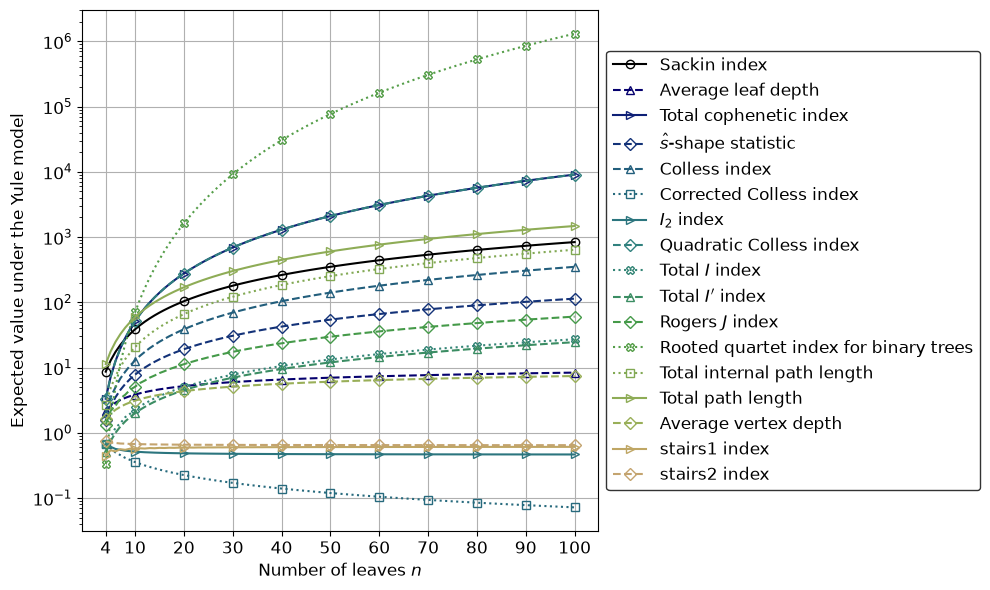

In [3]:
# Plot the means on a semilogy scale
marker_x = np.array([4, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])
plt.figure(figsize=(10, 6))
for i, index in enumerate(indices):
    params = plot_params(index)
    plt.semilogy(N, mean[:, i], label=params['label'], 
                 linestyle = params['linestyle'], 
                 marker = params['marker'], markevery=marker_x - min_n, mfc='none',
                 color = params['color'])

plt.xlabel('Number of leaves $n$', fontsize=12)
plt.ylabel('Expected value under the Yule model', fontsize=12)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize = 12, edgecolor = 'black')
# Fontsize for the x and y axes
plt.xticks(marker_x, fontsize=12)
plt.yticks(fontsize=12)
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(parent_dir, 'plots', 'meanPlot.png'), dpi=300, bbox_inches='tight')
plt.show()

# Figure 3: variance of 17 balance indices represented by the daughter-number basis

In [4]:
# This block may take a while (~1-2 minute on my machines)
variances = []
min_n = 4
max_n = 100
indices = BalanceIndexCoefficients().get_daughter_labels()

# For all n in the range, we will compute the variances of all basis indices under daughter basis
N = range(min_n, max_n + 1)
for n in N:
    # Daughter-number coefficients
    daughter_coef = BalanceIndexCoefficients(n).get_daughter_coefficients()
    matrix_of_coef= np.array(list(daughter_coef.values()))

    # Covariance matrix of basis
    daughter_cov = daughter_cov_matrix(n)

    # Calculate the outer product to find all covariances
    cov_matrix = matrix_of_coef @ daughter_cov @ matrix_of_coef.T
    variances.append(np.diag(cov_matrix))
    

variances = np.array(variances)

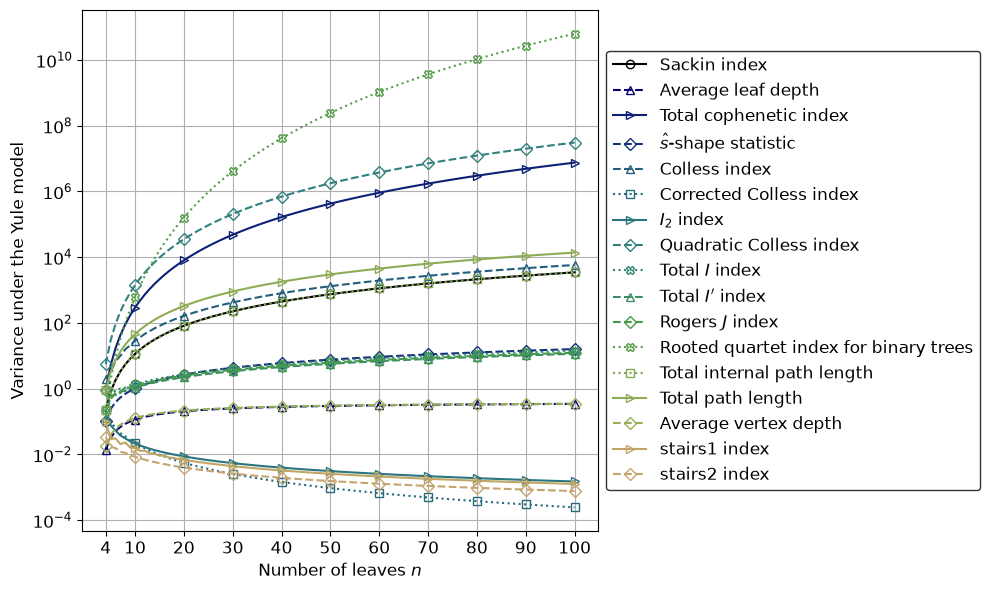

In [5]:
# Plot the variances on a semilogy scale
marker_x = np.array([4, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])
plt.figure(figsize=(10, 6))
for i, index in enumerate(indices):
    params = plot_params(index)
    plt.semilogy(N, variances[:, i], label=params['label'], 
                 linestyle = params['linestyle'], 
                 marker = params['marker'], markevery=marker_x - min_n, mfc='none',
                 color = params['color'])

plt.xlabel('Number of leaves $n$', fontsize=12)
plt.ylabel('Variance under the Yule model', fontsize=12)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize = 12, edgecolor='black')
# Fontsize for the x and y axes
plt.xticks(marker_x, fontsize=12)
plt.yticks(fontsize=12)
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(parent_dir, 'plots', 'variancePlot.png'), dpi=300, bbox_inches='tight')
plt.show()

# Plot (not used currently): Coefficient of variation for all indices

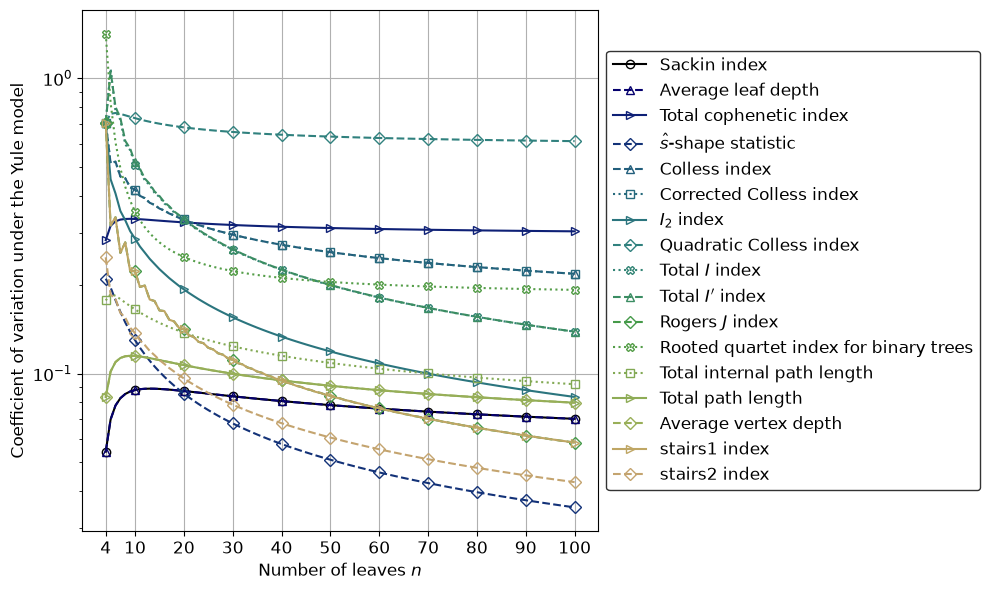

In [6]:
# Plot the coefficient of variation (CV = std / mean) on a semilogy scale
marker_x = np.array([4, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])
plt.figure(figsize=(10, 6))
for i, index in enumerate(indices):
    params = plot_params(index)
    plt.semilogy(N, np.sqrt(variances[:, i]) / mean[:, i], label=params['label'], 
                 linestyle = params['linestyle'], 
                 marker = params['marker'], markevery=marker_x - min_n, mfc='none',
                 color = params['color'])

plt.xlabel('Number of leaves $n$', fontsize=12)
plt.ylabel('Coefficient of variation under the Yule model', fontsize=12)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize = 12, edgecolor='black')
# Fontsize for the x and y axes
plt.xticks(marker_x, fontsize=12)
plt.yticks(fontsize=12)
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(parent_dir, 'plots', 'coefficient_of_variation_Plot.png'), dpi=300, bbox_inches='tight')
plt.show()

# Alternate plot: Make one plot for all indices with one legend

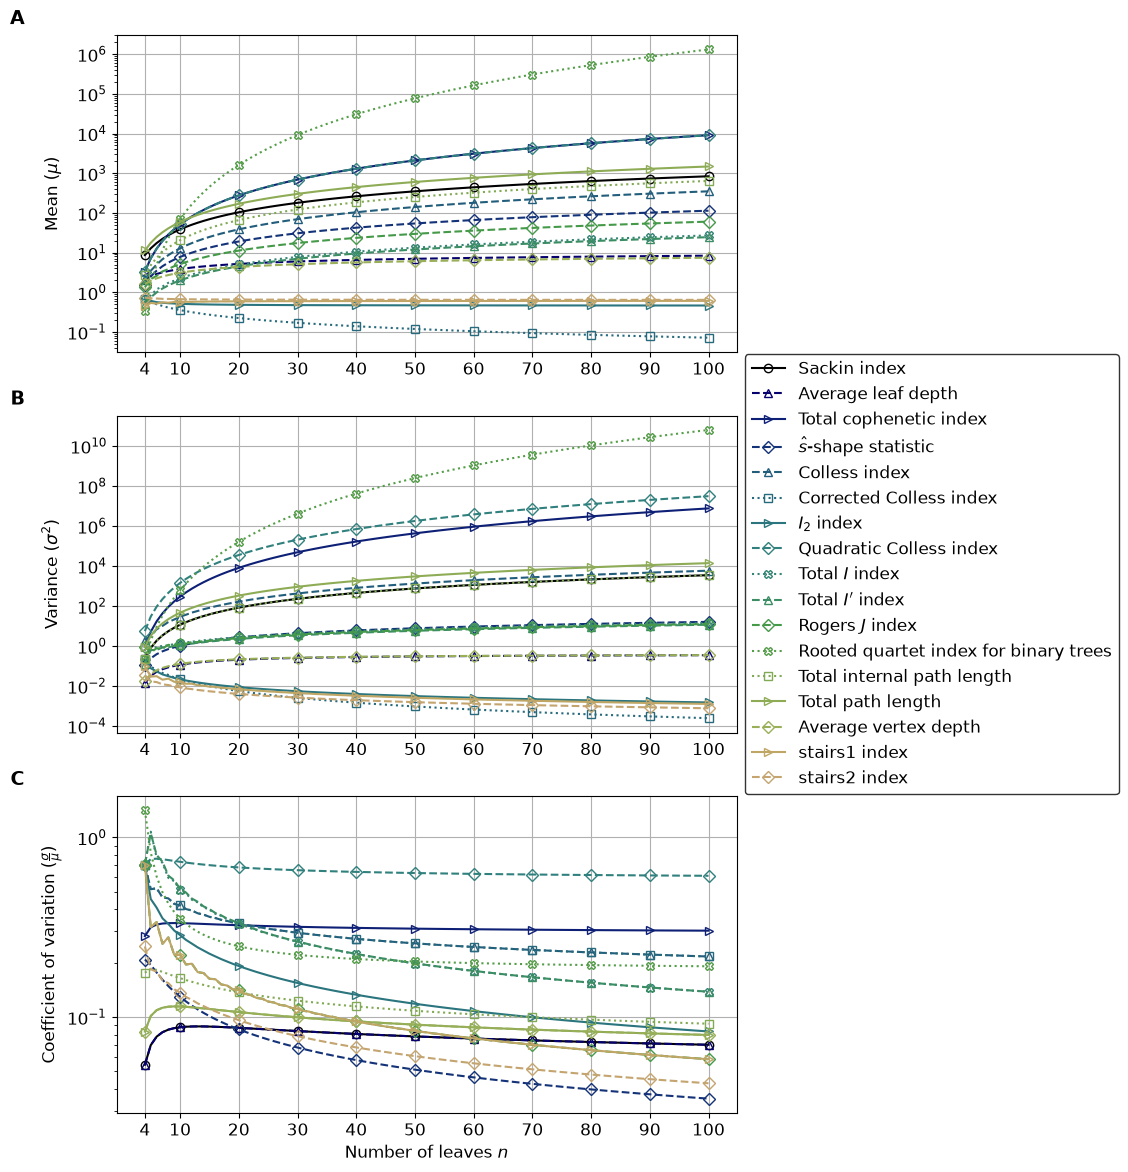

In [7]:
fig, ax = plt.subplots(3, 1, figsize = (8, 14))

marker_x = np.array([4, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])

# Mean plot at top
for i, index in enumerate(indices):
    params = plot_params(index)
    ax[0].semilogy(N, mean[:, i], label=params['label'], 
                    linestyle = params['linestyle'], 
                    marker = params['marker'], markevery=marker_x - min_n, mfc='none',
                    color = params['color'])

    ax[1].semilogy(N, variances[:, i], label=params['label'],
                    linestyle = params['linestyle'],
                    marker = params['marker'], markevery=marker_x - min_n, mfc='none',
                    color = params['color'])

    ax[2].semilogy(N, np.sqrt(variances[:, i]) / mean[:, i], label=params['label'],
                    linestyle = params['linestyle'],
                    marker = params['marker'], markevery=marker_x - min_n, mfc='none',
                    color = params['color'])
# Label the axes with titles
labels = ['A', 'B', 'C']

for a, label in zip(ax, labels):
    a.text(
        -0.16, 1.02, label,
        transform=a.transAxes,  # coordinates relative to this subplot
        fontsize=14,
        fontweight='bold',
        ha='center',
        va='bottom',
    )

# Xticks
ax[0].set_xticks(marker_x)
ax[1].set_xticks(marker_x)
ax[2].set_xticks(marker_x)

ax[2].set_xlabel('Number of leaves $n$', fontsize=12)
ax[0].set_ylabel('Mean $(\\mu)$', fontsize=12)
ax[1].set_ylabel('Variance $(\\sigma^2)$', fontsize=12)
ax[2].set_ylabel('Coefficient of variation $(\\frac{\\sigma}{\\mu})$', fontsize=12)

# Fontsize for the x and y axes
for a in ax:
    a.tick_params(axis='both', which='major', labelsize=12)
    a.grid(True)

# Legend for the middle plot
ax[1].legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize = 12, edgecolor='black')

plt.savefig(os.path.join(parent_dir, 'plots', 'mean_variance_cv_plot.png'), dpi=300, bbox_inches='tight')
plt.show()

# Plot 4a: correlation matrix

In [8]:
n = 100

# Daughter-number coefficients
indices = BalanceIndexCoefficients().get_daughter_labels()
daughter_coef = BalanceIndexCoefficients(n).get_daughter_coefficients()
matrix_of_coef= np.array(list(daughter_coef.values()))

# Covariance matrix of basis
daughter_cov = daughter_cov_matrix(n)

# Calculate the outer product to find all covariances
cov_matrix = matrix_of_coef @ daughter_cov @ matrix_of_coef.T

# Use cov_matrix_basis to get the correlation matrix
corr_matrix = cov_matrix/ np.sqrt(np.outer(np.diag(cov_matrix), np.diag(cov_matrix)))

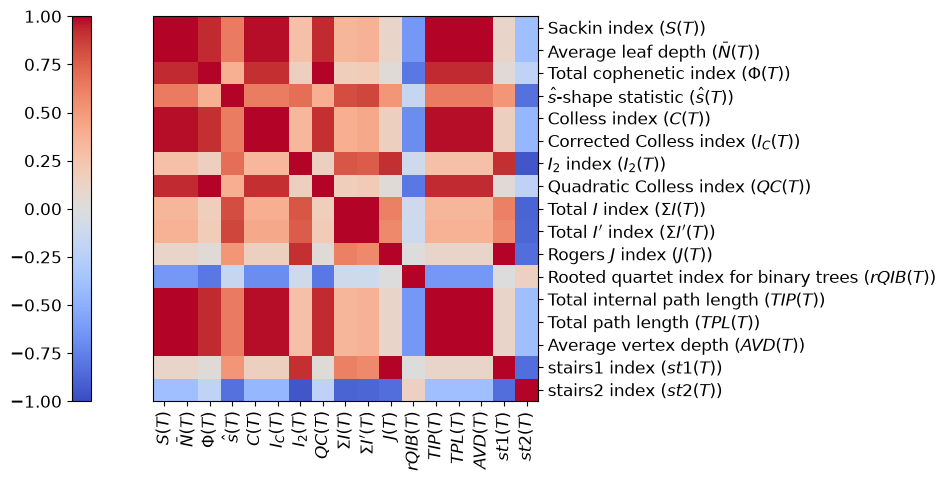

In [9]:
# Plot the correlation matrix
plt.figure(figsize=(8, 5))
plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
# Make ticks of the colorbar fontsize 12
plt.colorbar(location='left').ax.tick_params(labelsize=12)

# For this plot, make the labels equal to the formulas rather than names
plotting_labels = [plot_params(index)['formula'] for index in indices]
full_labels = []
for index in indices:
    full_labels.append(index + ' (' + plot_params(index)['formula'] + ')')

plt.xticks(ticks=np.arange(len(indices)), labels=plotting_labels, rotation=90, fontsize=12)
plt.yticks(ticks=np.arange(len(indices)), labels=full_labels, fontsize=12)
# Move yticks and labels to right side
plt.gca().yaxis.tick_right()
plt.gca().yaxis.set_label_position('right')

# plt.title('Correlation matrix of balance indices (daughter basis), n = ' + str(n))
# plt.tight_layout()
plt.savefig(os.path.join(parent_dir, 'plots', 'correlation_matrix_daughter_basis_n100.png'), bbox_inches='tight', dpi=300)
plt.show()

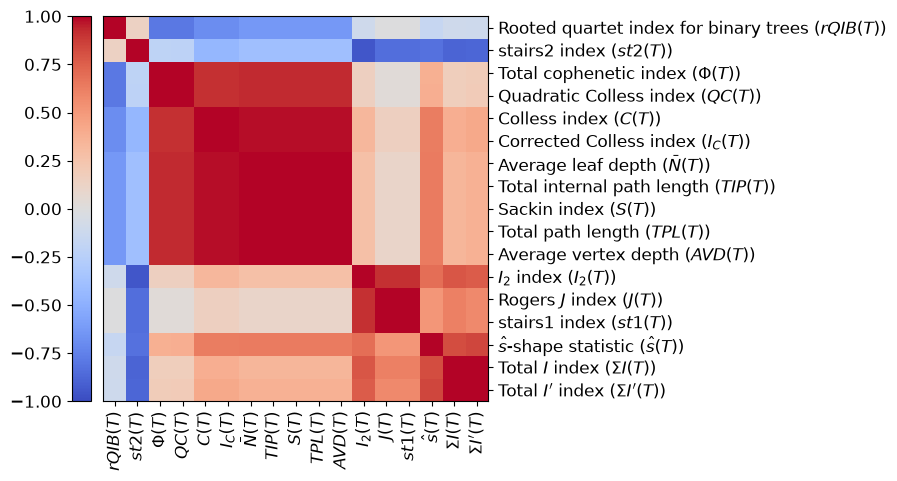

In [10]:
# Now change order of rows and columns to cluster the indices by correlation
from scipy.cluster.hierarchy import linkage, leaves_list

# Use linkage to cluster the correlation matrix
Z = linkage(corr_matrix, method = 'ward', metric = 'euclidean')

# Use leaves_list to get the order of the leaves
order = leaves_list(Z)

# Reorder the correlation matrix and labels according to the clustering
reordered_corr_matrix = corr_matrix[order][:, order]
# Reorder the labels according to the clustering
reordered_labels = [plotting_labels[i] for i in order]
reordered_full_labels = [full_labels[i] for i in order]

# Plot the reordered correlation matrix
plt.figure(figsize=(8, 5))
plt.imshow(reordered_corr_matrix, cmap='coolwarm', vmin=-1, vmax=
1)
# Make ticks of the colorbar fontsize 12
plt.colorbar(location='left', pad=0.02).ax.tick_params(labelsize=12)

# Labels for the reordered correlation matrix
plt.xticks(ticks=np.arange(len(indices)), labels=reordered_labels, rotation=90, fontsize=12)
plt.yticks(ticks=np.arange(len(indices)), labels=reordered_full_labels, fontsize=12)

# Move yticks and labels to right side
plt.gca().yaxis.tick_right()
plt.gca().yaxis.set_label_position('right')


plt.show()

In [11]:
order

array([11, 16,  2,  7,  4,  5,  1, 12,  0, 13, 14,  6, 10, 15,  3,  8,  9],
      dtype=int32)

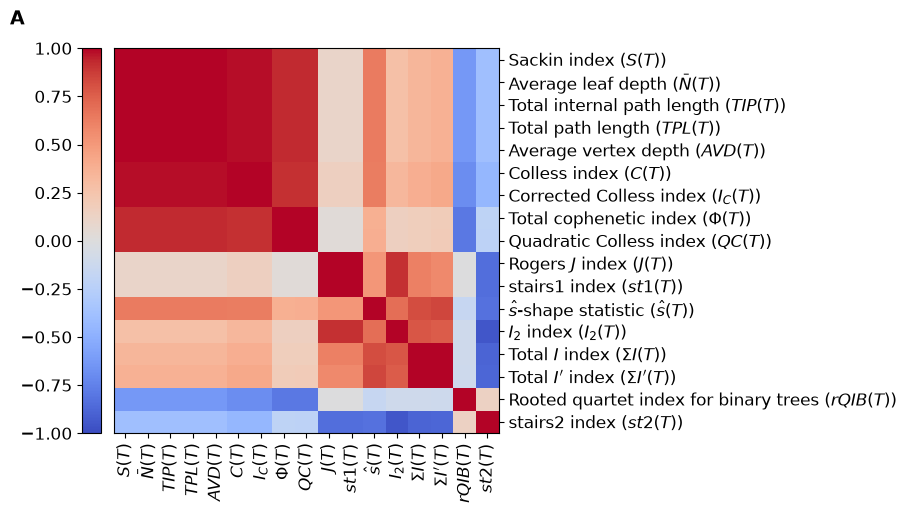

In [12]:
good_order = np.array([
     0,  1, 12, 13, 14, 4, 5, 2, 7, 10, 15,  3,  6,  8,  9, 11, 16
])

# Make the reordered correlation matrix using the good_order
reordered_corr_matrix2 = corr_matrix[good_order][:, good_order]

# Reordered labels
reordered_labels2 = [plotting_labels[i] for i in good_order]
reordered_full_labels2 = [full_labels[i] for i in good_order]

# Plot the reordered correlation matrix
plt.figure(figsize=(8, 5))
plt.imshow(reordered_corr_matrix2, cmap='coolwarm', vmin=-1, vmax=
1)
# Make ticks of the colorbar fontsize 12
plt.colorbar(location='left', pad=0.02).ax.tick_params(labelsize=12)

# Labels for the reordered correlation matrix
plt.xticks(ticks=np.arange(len(indices)), labels=reordered_labels2, rotation=90, fontsize=12)
plt.yticks(ticks=np.arange(len(indices)), labels=reordered_full_labels2, fontsize=12)

# Move yticks and labels to right side
plt.gca().yaxis.tick_right()
plt.gca().yaxis.set_label_position('right')

plt.text(
        -0.25, 1.05, 'A',
        transform=plt.gca().transAxes,  # coordinates relative to this subplot
        fontsize=14,
        fontweight='bold',
        ha='center',
        va='bottom',
    )

plt.savefig(os.path.join(parent_dir, 'plots', 'correlation_matrix_daughter_basis_n100_reordered.png'), bbox_inches='tight', dpi=300)
plt.show()

# Plot 4b: MDS of the correlation matrix

In [13]:
from sklearn.manifold import MDS
from sklearn.metrics import pairwise_distances

# Use MDS to cluster indices based on correlation matrix
indices = BalanceIndexCoefficients().get_daughter_labels()
# Convert the correlation matrix into a distance matrix
dist_squared = 2 * (1 - corr_matrix) 
zeroes_dist_squared = np.where(np.abs(dist_squared) < 1e-14, 0, dist_squared)
distance_matrix = np.sqrt(zeroes_dist_squared)

# Calculate the mds
mds = MDS(n_components=2, metric='precomputed', init = 'classical_mds')
coords = mds.fit_transform(distance_matrix)

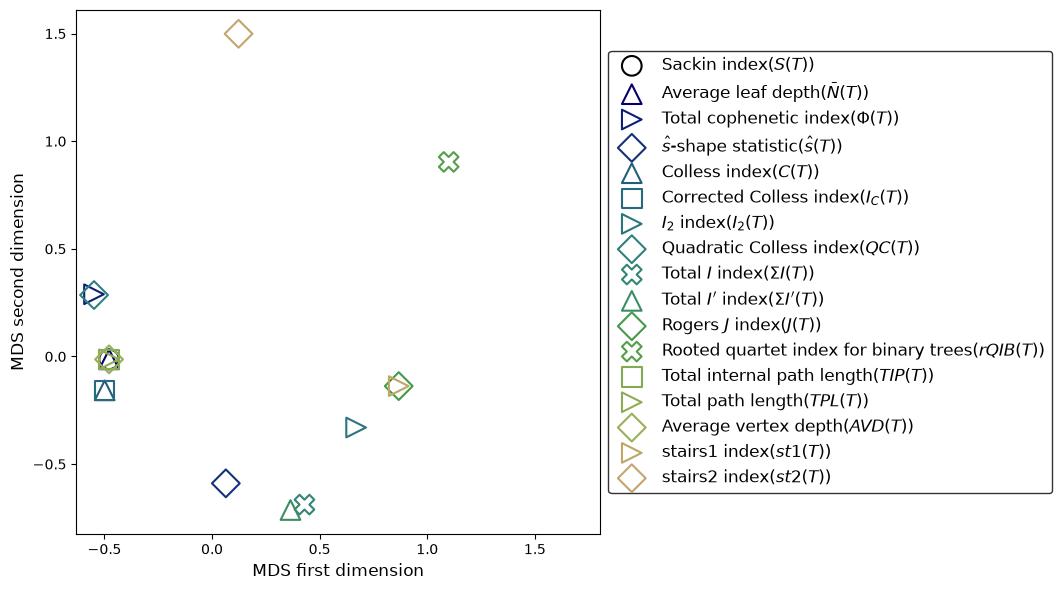

In [14]:
# Now plot the points
plt.figure(figsize=(10,6))

# Full labels (name and formula)
full_labels = []
for index in indices:
    full_labels.append(index + '(' + plot_params(index)['formula'] + ')')

for i in range(len(coords)):
    params = plot_params(indices[i])
    plt.scatter(coords[i, 0], coords[i, 1], label = full_labels[i], 
                color = params['color'], 
                marker = params['marker'], fc='none', linewidth=1.5,
                s = 200)
plt.xlabel("MDS first dimension", fontsize=12)
plt.ylabel("MDS second dimension", fontsize=12)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize = 12, edgecolor='black')
plt.axis('square')
plt.tight_layout()

# plt.savefig(os.path.join(parent_dir, 'plots', 'MDS_plot_corr_matrix.png'))
plt.show()

In [15]:
indices = BalanceIndexCoefficients().get_daughter_labels()
coords = mds.fit_transform(distance_matrix)

# Because some of the indices overlap, we are going to merge them so only one MDS plot appears
sackin_like = ['Sackin index', 
               'Average leaf depth', 
               'Total internal path length', 
               'Total path length', 
               'Average vertex depth']
colless_like = ['Colless index',
                'Corrected Colless index']
j_like = ['Rogers $J$ index',
          'stairs1 index']

clusters = [sackin_like, colless_like, j_like]

# Remove the duplicate entries from our indices and our coords arrays
# Change the name of the representative using this dictionary
for cluster in clusters:
    for j in range(1, len(cluster)):
        i = indices.index(cluster[j])
        indices.remove(cluster[j])
        coords = np.delete(coords, i, axis=0)
    indices[indices.index(cluster[0])] += " cluster" 

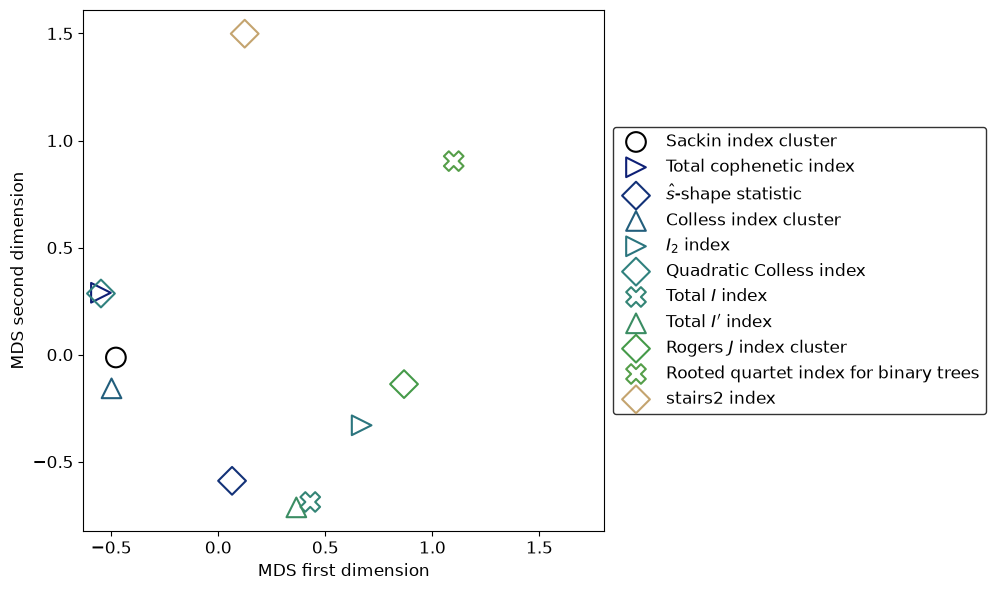

In [16]:
# Make a plot where we do not duplicate cluster entries
plt.figure(figsize=(10,6))

for i in range(len(coords)):
    index = indices[i]
    if index[-7:] == 'cluster':
        params = plot_params(index[:-8])
    else:
        params = plot_params(index)
    plt.scatter(coords[i, 0], coords[i, 1], label = indices[i], 
                color = params['color'], 
                marker = params['marker'],fc='none', linewidth=1.5,
                s = 200)



plt.xlabel("MDS first dimension", fontsize=12)
plt.ylabel("MDS second dimension", fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize = 12, edgecolor='black')
plt.axis('square')
plt.tight_layout()

plt.savefig(os.path.join(parent_dir, 'plots', 'MDS_plot_corr_matrix_with_clusters.png'), bbox_inches='tight', dpi=300)
plt.show()

# Figure 3 all in one plot
I used AI for the following block of code, to help combine the plots I made above in a satisfactory way

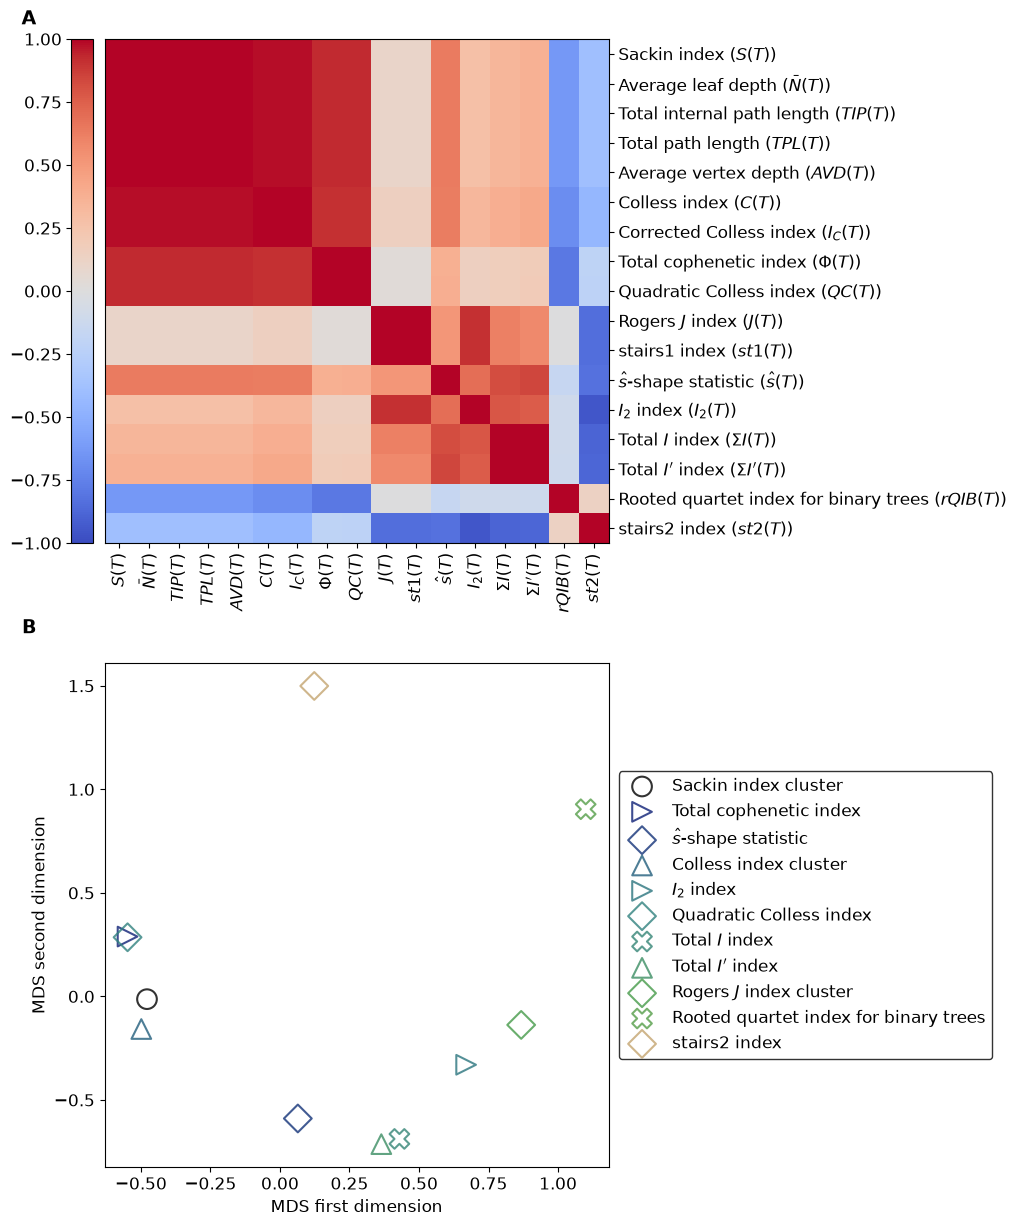

In [17]:

# A square figure makes these manually specified axes square.
fig = plt.figure(figsize=(12, 12))

plot_left = 0.15
plot_size = 0.42

bottom_y = 0.08
top_y = 0.60       

cbar_width = 0.018
cbar_gap = 0.01  

ax0 = fig.add_axes([plot_left, top_y, plot_size, plot_size])
ax1 = fig.add_axes([plot_left, bottom_y, plot_size, plot_size])

cax = fig.add_axes([
    plot_left - cbar_gap - cbar_width,
    top_y,
    cbar_width,
    plot_size
])

# ---------------------------------------------------------------------
# Top plot: reordered correlation matrix
# ---------------------------------------------------------------------
indices = BalanceIndexCoefficients().get_daughter_labels()

plotting_labels = [plot_params(index)["formula"] for index in indices]
full_labels = [
    index + " (" + plot_params(index)["formula"] + ")"
    for index in indices
]

reordered_labels2 = [plotting_labels[i] for i in good_order]
reordered_full_labels2 = [full_labels[i] for i in good_order]

im = ax0.imshow(
    reordered_corr_matrix2,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="equal"
)

# Colorbar has exactly the same height as the matrix axes.
cbar = fig.colorbar(im, cax=cax)

# Ensure colorbar labels face away from the plot.
cbar.ax.yaxis.set_ticks_position("left")
cbar.ax.yaxis.set_label_position("left")
cbar.ax.tick_params(labelsize=12, pad=3)

ax0.set_xticks(np.arange(len(indices)))
ax0.set_xticklabels(reordered_labels2, rotation=90, fontsize=12)

ax0.set_yticks(np.arange(len(indices)))
ax0.set_yticklabels(reordered_full_labels2, fontsize=12)

# Put matrix labels on its right side.
ax0.yaxis.tick_right()
ax0.yaxis.set_label_position("right")

# ---------------------------------------------------------------------
# Bottom plot: MDS scatter
# ---------------------------------------------------------------------
# Need to redefine indices
indices = BalanceIndexCoefficients().get_daughter_labels()
coords = mds.fit_transform(distance_matrix)

# Because some of the indices overlap, we are going to merge them so only one MDS plot appears
sackin_like = ['Sackin index', 
               'Average leaf depth', 
               'Total internal path length', 
               'Total path length', 
               'Average vertex depth']
colless_like = ['Colless index',
                'Corrected Colless index']
j_like = ['Rogers $J$ index',
          'stairs1 index']

clusters = [sackin_like, colless_like, j_like]

# Remove the duplicate entries from our indices and our coords arrays
# Change the name of the representative using this dictionary
for cluster in clusters:
    for j in range(1, len(cluster)):
        i = indices.index(cluster[j])
        indices.remove(cluster[j])
        coords = np.delete(coords, i, axis=0)
    indices[indices.index(cluster[0])] += " cluster" 

# Now plot
for i in range(len(coords)):
    index = indices[i]

    if index.endswith("cluster"):
        params = plot_params(index[:-8])
    else:
        params = plot_params(index)

    ax1.scatter(
        coords[i, 0],
        coords[i, 1],
        label=index,
        color=params["color"],
        alpha=0.8,
        marker=params["marker"], fc='none', linewidth=1.5,
        s=200,
    )

ax1.set_xlabel("MDS first dimension", fontsize=12)
ax1.set_ylabel("MDS second dimension", fontsize=12)
ax1.tick_params(axis="both", which="major", labelsize=12)

# Keep the *box* square, while allowing your MDS limits to remain unchanged.
ax1.set_box_aspect(1)

# Put the legend just outside the right edge of ax1.
ax1.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    fontsize=12,
    edgecolor="black",
    borderaxespad=0
)

# ---------------------------------------------------------------------
# Panel labels
# ---------------------------------------------------------------------
ax0.text(
    -0.15, 1.02, "A",
    transform=ax0.transAxes,
    fontsize=14,
    fontweight="bold",
    ha="center",
    va="bottom"
)

ax1.text(
    -0.15, 1.05, "B",
    transform=ax1.transAxes,
    fontsize=14,
    fontweight="bold",
    ha="center",
    va="bottom"
)


plt.savefig(os.path.join(parent_dir, 'plots', 'correlation_matrix_and_MDS_plot.png'), bbox_inches='tight', dpi=1000)
plt.show()

# Appendix figures

In [18]:
import scipy.linalg as la
import src.tree_bstats.indices as indices
import pandas as pd

# Figure C1: Errors when projecting indices onto daughter-number basis

In [19]:
# Pick list of indices to study (all not represented by clade-number basis, and exclude Colijn-Plazzotta)
all_indices = Tree().get_balance_names()
my_indices = Tree().get_balance_names()
# First, we remove the indices that are represented by the clade-number basis
clade_labels = BalanceIndexCoefficients().get_clade_labels()
exclude = clade_labels + ['Colijn-Plazzotta rank']
for label in exclude:
    my_indices.remove(label)

In [20]:
# Next, for all k=6,...,16, we use least squares to find approximate solution and track residual error for each index

k0 = 6
n = 16
trees = UnlabelledTree(n)

clade_residuals = np.zeros((n-k0 + 1, len(my_indices)))
clade_regression_results = {name: [] for name in my_indices}

for k in range(k0, n+1):

    clade_numbers, _, balance_indices, weights = trees.get_data(k)

    clade_numbers = np.array(clade_numbers)

    
    # clade_numbers = clade_numbers[:, :-1] # uncomment to remove the last column of the clade_numbers (since this is redundant and always equal to 1)
    balance_indices = pd.DataFrame(balance_indices, columns=all_indices)
    # drop Colijn-Plazzatto index along with all columns that are represented by the clade-number basis
    balance_indices = balance_indices.drop(columns=exclude)
    weights = np.array(weights)

    # weight the data by weights before performing least squares
    W = np.sqrt(np.diag(weights))
    Bw = np.dot(W, balance_indices.values)
    Cw = np.dot(W, clade_numbers)

    for i in range(len(my_indices)):
        # Project each balance index onto the clade number axis
        X = la.lstsq(Cw, Bw[:, i])[0]
        clade_regression_results[my_indices[i]].append(X)
        B_proj = np.dot(Cw, X)
        residual = np.sum((B_proj - Bw[:, i])**2)

        # To compare residuals across indices, we divide by the magnitude of the balance index
        residual /= la.norm(Bw[:, i])
        clade_residuals[k-k0, i] = residual


Trees generated with counts  [1, 1, 1, 2, 3, 6, 11, 23, 46, 98, 207, 451, 983, 2179, 4850, 10905]


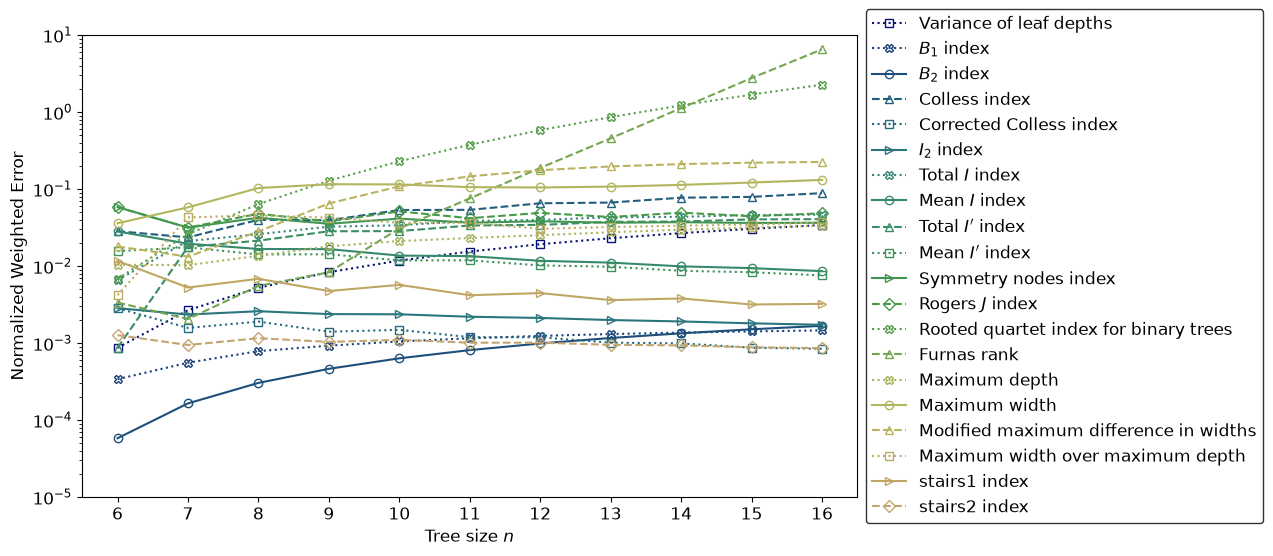

In [21]:
# Plot these residual curves
# Now plot the residuals

plt.figure(figsize=(10, 6))
for i in range(len(my_indices)):
    params = plot_params(my_indices[i])
    plt.semilogy(range(k0, n+1), clade_residuals[:, i], label=params['label'], 
                 linestyle = params['linestyle'], 
                 marker = params['marker'], mfc='none',
                 color = params['color'])
plt.xlabel('Tree size $n$', fontsize = 12)
plt.ylabel('Normalized Weighted Error', fontsize = 12)
plt.ylim(1e-5, 1e1)
# Move legend to far right
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize = 12, frameon=True, edgecolor = 'black')
plt.xticks(np.arange(k0, n+1),fontsize = 12)
plt.yticks(fontsize = 12)
# plt.title('Error in the best approximation of statistics by the clade-number basis', fontsize = 20)
plt.savefig(os.path.join(parent_dir, 'plots', 'clade_basis_projection_residuals.png'), bbox_inches='tight', dpi=300)
plt.show()

# Figure C2: Errors when projecting balance indices onto the daughter-number basis

In [22]:
# Pick list of indices to study (all not represented by daughter-number basis, and exclude Colijn-Plazzotta)
all_indices = Tree().get_balance_names()
my_indices = Tree().get_balance_names()
# First, we remove the indices that are represented by the daughter-number basis
daughter_labels = BalanceIndexCoefficients().get_daughter_labels()
exclude = daughter_labels + ['Colijn-Plazzotta rank']
for label in exclude:
    my_indices.remove(label)

In [23]:
# Next, for all k=6,...,16, we use least squares to find approximate solution and track residual error for each index

k0 = 6
n = 16
trees = UnlabelledTree(n)

daughter_residuals = np.zeros((n-k0 + 1, len(my_indices)))
daughter_regression_results = {name: [] for name in my_indices}

for k in range(k0, n+1):

    _, daughter_numbers, balance_indices, weights = trees.get_data(k)

    daughter_numbers = np.array(daughter_numbers)

    
    # daughter_numbers = daughter_numbers[:, :-1] # uncomment to remove the last column of the daughter_numbers (since this is redundant and always equal to 1)
    balance_indices = pd.DataFrame(balance_indices, columns=all_indices)
    # drop Colijn-Plazzatto index along with all columns that are represented by the daughter-number basis
    balance_indices = balance_indices.drop(columns=exclude)
    weights = np.array(weights)

    # weight the data by weights before performing least squares
    W = np.sqrt(np.diag(weights))
    Bw = np.dot(W, balance_indices.values)
    Dw = np.dot(W, daughter_numbers)

    for i in range(len(my_indices)):
        # Project each balance index onto the daughter number axis
        X = la.lstsq(Dw, Bw[:, i])[0]
        daughter_regression_results[my_indices[i]].append(X)
        B_proj = np.dot(Dw, X)
        residual = np.sum((B_proj - Bw[:, i])**2)

        # To compare residuals across indices, we divide by the magnitude of the balance index
        residual /= la.norm(Bw[:, i])
        daughter_residuals[k-k0, i] = residual


Trees generated with counts  [1, 1, 1, 2, 3, 6, 11, 23, 46, 98, 207, 451, 983, 2179, 4850, 10905]


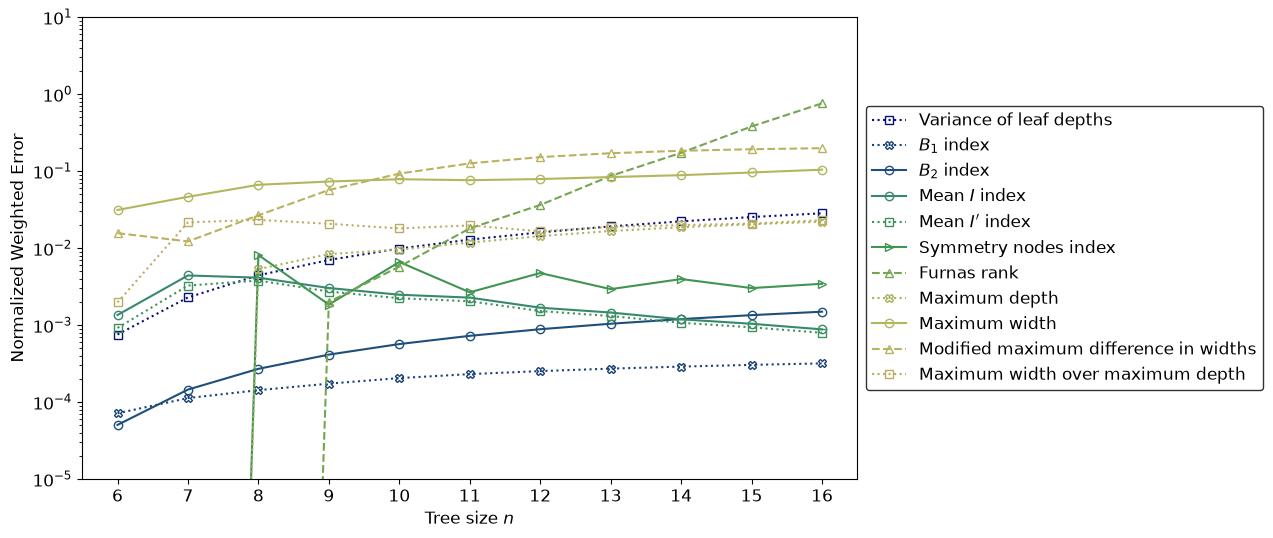

In [24]:
plt.figure(figsize=(10, 6))
for i in range(len(my_indices)):
    params = plot_params(my_indices[i])
    plt.semilogy(range(k0, n+1), daughter_residuals[:, i], label=params['label'], 
                 linestyle = params['linestyle'], 
                 marker = params['marker'], mfc='none',
                 color = params['color'])
plt.xlabel('Tree size $n$', fontsize = 12)
plt.ylabel('Normalized Weighted Error', fontsize = 12)
plt.ylim(1e-5, 1e1)
# Move legend to far right
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize = 12, frameon=True, edgecolor = 'black')
plt.xticks(np.arange(k0, n+1), fontsize = 12)
plt.yticks(fontsize = 12)
# plt.title('Error in the best approximation of statistics by the daughter-number basis', fontsize = 20)
plt.savefig(os.path.join(parent_dir, 'plots', 'daughter_basis_projection_residuals.png'), bbox_inches='tight', dpi=300)
plt.show()

## Repeat the plot with a broken axis. (This was generated from the above code with help from AI tools)

C:\Users\djbauman\AppData\Local\Temp\ipykernel_27664\3310254371.py:96: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim(ymin, ymax)


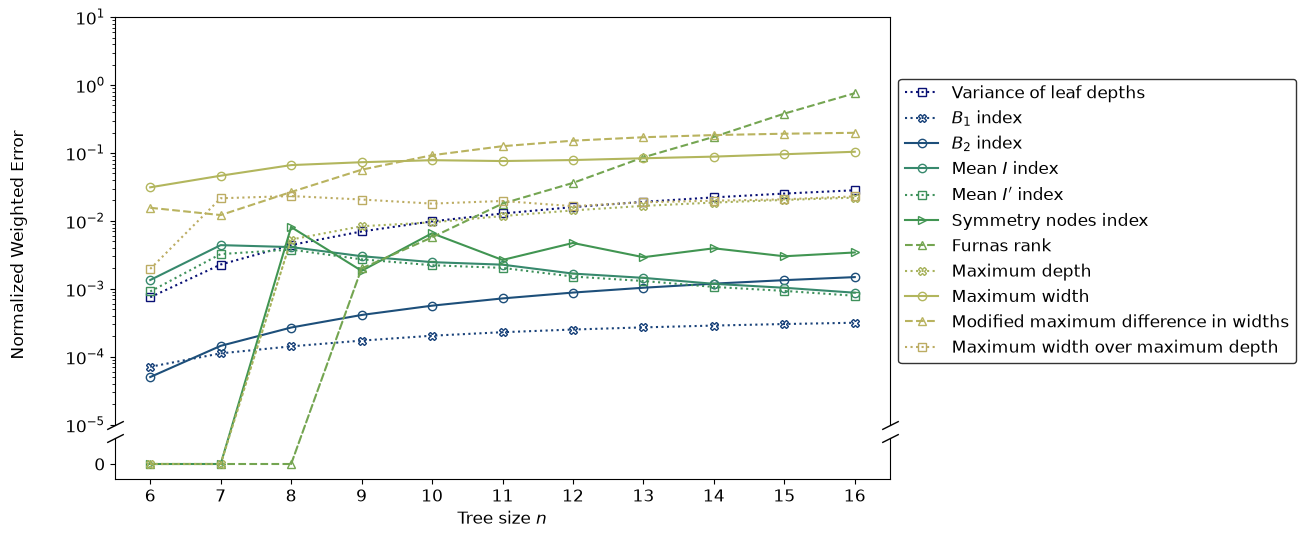

In [25]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import ConnectionPatch
from matplotlib.ticker import FixedLocator, FixedFormatter, NullLocator

x = np.arange(k0, n + 1)

zero_tol = 1e-12       # Choose based on your numerical precision
ymin, ymax = 1e-5, 1e1
zero_position = ymin / 100  # Plotting placeholder, NOT a residual value

fig, (ax, ax_zero) = plt.subplots(
    2, 1,
    sharex=True,
    figsize=(10, 6),
    gridspec_kw={
        "height_ratios": [1, 0.10],
        "hspace": 0.06,
    },
)

# Both panels use the same internal scale so the curves can be
# drawn continuously, then clipped at each panel's boundaries.
ax.set_yscale("log")
ax_zero.set_yscale("log")

for i, index in enumerate(my_indices):
    params = plot_params(index)

    y = np.asarray(daughter_residuals[:, i], dtype=float)
    is_zero = np.isclose(y, 0.0, atol=zero_tol, rtol=0.0)

    style = dict(
        linestyle=params["linestyle"],
        marker=params["marker"],
        mfc="none",
        color=params["color"],
    )

    # Draw nonzero runs in the upper panel.
    # NaNs prevent automatic connections to the zero points.
    upper_line, = ax.plot(
        x,
        np.where(is_zero, np.nan, y),
        label=params["label"],
        **style,
    )

    # Draw zero runs in the lower panel.
    ax_zero.plot(
        x,
        np.where(is_zero, zero_position, np.nan),
        **style,
    )

    # Connect each zero/nonzero transition with ONE straight line
    # in screen space, rather than two differently sloped segments.
    for j in range(len(x) - 1):
        if is_zero[j] == is_zero[j + 1]:
            continue

        # Skip missing/nonfinite data.
        if not np.all(np.isfinite(y[j:j + 2])):
            continue

        axes_a = ax_zero if is_zero[j] else ax
        axes_b = ax_zero if is_zero[j + 1] else ax

        point_a = (
            x[j],
            zero_position if is_zero[j] else y[j],
        )
        point_b = (
            x[j + 1],
            zero_position if is_zero[j + 1] else y[j + 1],
        )

        connector = ConnectionPatch(
            xyA=point_a,
            xyB=point_b,
            coordsA="data",
            coordsB="data",
            axesA=axes_a,
            axesB=axes_b,
            arrowstyle="-",
            connectionstyle="arc3,rad=0",  # Straight line
            shrinkA=0,
            shrinkB=0,
            color=params["color"],
            linestyle=params["linestyle"],
            linewidth=upper_line.get_linewidth(),
            clip_on=False,
        )
        fig.add_artist(connector)
ax.set_ylim(ymin, ymax)
ax_zero.set_ylim(zero_position / 1.5, zero_position * 2)

# The lower panel has only one labeled level: zero.
ax_zero.yaxis.set_major_locator(FixedLocator([zero_position]))
ax_zero.yaxis.set_major_formatter(FixedFormatter(["0"]))
ax_zero.yaxis.set_minor_locator(NullLocator())

# Hide the adjoining spines and the upper panel's x-axis ticks.
ax.spines["bottom"].set_visible(False)
ax_zero.spines["top"].set_visible(False)
ax.tick_params(axis="x", which="both", bottom=False, labelbottom=False)

# Diagonal break marks on both sides of the axes.
break_style = dict(
    marker=[(-1, -0.5), (1, 0.5)],
    markersize=12,
    linestyle="none",
    color="black",
    mec="black",
    mew=1,
    clip_on=False,
)
ax.plot([0, 1], [0, 0], transform=ax.transAxes, **break_style)
ax_zero.plot([0, 1], [1, 1], transform=ax_zero.transAxes, **break_style)

ax_zero.set_xlabel(r"Tree size $n$", fontsize=12)
fig.supylabel("Normalized Weighted Error", fontsize=12)

ax_zero.set_xticks(x)
for panel in (ax, ax_zero):
    panel.tick_params(labelsize=12)

ax.legend(
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    fontsize=12,
    frameon=True,
    edgecolor="black",
)

fig.savefig(
    os.path.join(
        parent_dir, "plots", "daughter_basis_projection_residuals_broken_axis.png"
    ),
    bbox_inches="tight",
    dpi=300,
)
plt.show()

# Plot C3: Best-fit coefficients for indices not represented by the daughter-number basis

In [26]:
# Pick list of indices to study (all not represented by clade-number basis, and exclude Colijn-Plazzotta and Furnas ranks)
all_indices = Tree().get_balance_names()
my_indices = Tree().get_balance_names()
# First, we remove the indices that are represented by the clade-number basis
clade_labels = BalanceIndexCoefficients().get_clade_labels()
exclude = clade_labels + ['Colijn-Plazzotta rank', 'Furnas rank']
for label in exclude:
    my_indices.remove(label)

In [27]:
# Run for all indices
all_indices = Tree().get_balance_names()
my_indices = Tree().get_balance_names()
exclude = ['Colijn-Plazzotta rank']
for label in exclude:
    my_indices.remove(label)

In [28]:
# Now we project each index onto the clade-number basis for n = 16
n = 16
trees = UnlabelledTree(n)

clade_regression_results = {}

clade_numbers, _, balance_indices, weights = trees.get_data(n)

clade_numbers = np.array(clade_numbers)
clade_numbers = clade_numbers[:, :-1] # uncomment to remove the last column of the clade_numbers (since this is redundant and always equal to 1)
balance_indices = pd.DataFrame(balance_indices, columns=all_indices)
# drop Colijn-Plazzatto index along with all columns that are represented by the clade-number basis
balance_indices = balance_indices.drop(columns=exclude)
weights = np.array(weights)

# weight the data by weights before performing least squares
W = np.sqrt(np.diag(weights))
Bw = np.dot(W, balance_indices.values)
Cw = np.dot(W, clade_numbers)

# Calculate the least squares solution for each index and store the results
for i in range(len(my_indices)):
    X = la.lstsq(Cw, Bw[:, i])[0]
    clade_regression_results[my_indices[i]] = X

Trees generated with counts  [1, 1, 1, 2, 3, 6, 11, 23, 46, 98, 207, 451, 983, 2179, 4850, 10905]


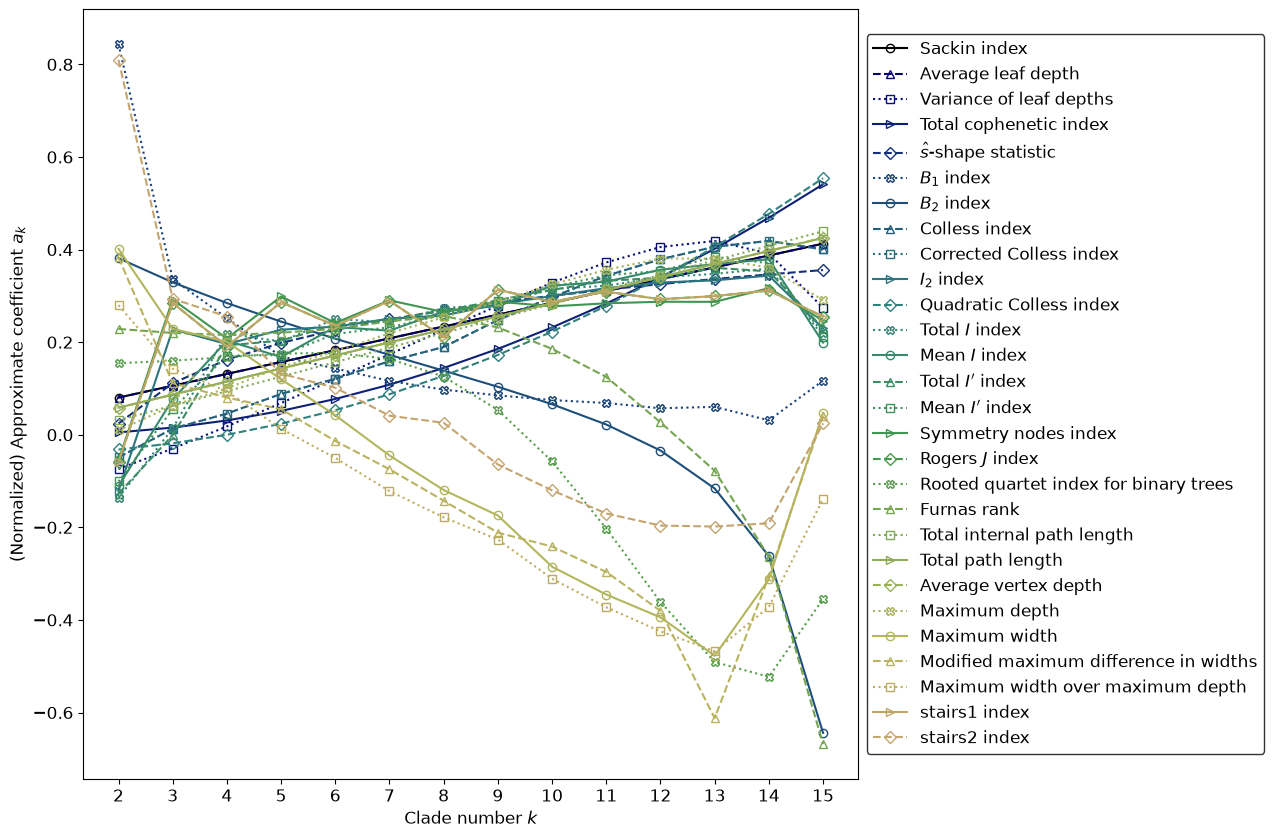

In [29]:
# Now, plot the coefficients for each index
plt.figure(figsize=(10, 10))

for index in my_indices:
    params = plot_params(index)
    y = clade_regression_results[index].flatten()
    # Normalize the coefficients so has magnitude 1
    y /= np.linalg.norm(y)
    plt.plot(range(2, n), y, label=params['label'], 
             linestyle = params['linestyle'], 
             marker = params['marker'], markevery=1, mfc='none',
             color = params['color'])

plt.xlabel('Clade number $k$', fontsize=12)
plt.ylabel('(Normalized) Approximate coefficient $a_k$', fontsize=12)
plt.xticks(np.arange(2, n), fontsize = 12)
plt.yticks(fontsize = 12)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize = 12, frameon=True, edgecolor = 'black')
# plt.tight_layout()
plt.savefig(os.path.join(parent_dir, 'plots', 'clade_basis_projection_coefficients.png'), bbox_inches='tight', dpi=300)
plt.show()

# 